In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Thư mục gốc của project
def find_project_dir(start: Path = Path.cwd()) -> Path:
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "data" / "raw" / "train.csv").is_file():
            return folder

    raise FileNotFoundError(
        f"Could not find the project (looked for data/raw/train.csv) from {start.resolve()}"
    )

PROJECT_DIR = find_project_dir()

# Tìm train.csv của bộ Credit Card Churn
DATA_FILE = None

for f in PROJECT_DIR.rglob("train.csv"):
    try:
        sample = pd.read_csv(f, nrows=5)

        if {
            "customer_id",
            "churn_3m"
        }.issubset(sample.columns):
            DATA_FILE = f
            break

    except Exception:
        continue

if DATA_FILE is None:
    raise FileNotFoundError(
        "Không tìm thấy train.csv của Credit Card Churn. "
        "Hãy kiểm tra lại PROJECT_DIR."
    )

# Đọc dữ liệu gốc
train_raw = pd.read_csv(DATA_FILE)

# Tạo bản dùng cho EDA
train = train_raw.copy()

## print("File dữ liệu:", DATA_FILE)
print("Kích thước dữ liệu:", train.shape)
print("Số cột:", len(train.columns))
print("\nDanh sách cột:")
print(train.columns.tolist())

display(train.head())

Kích thước dữ liệu: (12120, 24)
Số cột: 24

Danh sách cột:
['customer_id', 'bank_code', 'age', 'gender', 'province', 'occupation', 'income_month', 'card_type', 'open_date', 'credit_limit', 'annual_fee_waived', 'utilization_6m', 'txn_count_3m', 'txn_amount_3m', 'spend_change_pct', 'app_logins_30d', 'complaints_12m', 'late_payments_12m', 'salary_via_bank', 'other_bank_cards', 'promo_ended_60d', 'last_contact_channel', 'currency', 'churn_3m']


,customer_id,bank_code,age,gender,province,occupation,income_month,card_type,open_date,credit_limit,...,spend_change_pct,app_logins_30d,complaints_12m,late_payments_12m,salary_via_bank,other_bank_cards,promo_ended_60d,last_contact_channel,currency,churn_3m
0,CUSTI3FNUD,VB01,48.0,F,Hải Dương,self_employed,25.1,Gold,2026-04-09,55.0,...,-23.5,2.0,0,0,N,1.0,0,app,vnd,1
1,CUSOOYRASU,VB01,47.0,M,Hà Nội,Salaried,NaN,Classic,06/01/2024,30.0,...,-27.7,4.0,0,0,Y,1.0,0,app,VND,0
2,CUSQTUBJRJ,VB01,38.0,M,Long An,other,8.5,Cashback,02/08/2022,15.0,...,-20.7,8.0,0,0,N,0.0,1,none,VND,0
3,CUSD7I53QY,VB01,25.0,M,TP.HCM,self_employed,33.9,Cashback,12/05/2022,110.0,...,44.7,5.0,0,0,N,NaN,1,app,VND,0
4,CUS02NC6FN,VB01,32.0,m,TP.HCM,civil_servant,14.0,Cashback,03/07/2025,40.0,...,-28.0,4.0,0,0,N,0.0,0,none,VND,0


=== KIỂU DỮ LIỆU ===


,data_type
customer_id,object
bank_code,object
age,float64
gender,object
province,object
occupation,object
income_month,float64
card_type,object
open_date,object
credit_limit,float64


=== THỐNG KÊ DỮ LIỆU SỐ ===


,count,mean,std,min,25%,50%,75%,max
age,11724.0,3.974326e+01,2.993628e+01,0.00,31.0000,38.000,45.0000,9.990000e+02
income_month,10558.0,1.875843e+05,2.065907e+06,1.00,11.8000,17.700,26.1000,5.050000e+07
credit_limit,12120.0,1.094113e+06,1.052716e+07,10.00,25.0000,40.000,70.0000,3.850000e+08
annual_fee_waived,12120.0,5.075908e-01,4.999630e-01,0.00,0.0000,1.000,1.0000,1.000000e+00
utilization_6m,12120.0,3.248559e-01,7.247546e-01,-1.00,0.1380,0.272,0.4210,1.500000e+01
txn_count_3m,12120.0,1.891147e+01,1.026963e+01,1.00,12.0000,17.000,24.0000,1.010000e+02
txn_amount_3m,12120.0,2.534355e+01,2.880579e+01,-2.99,8.7175,16.760,31.6325,4.628100e+02
spend_change_pct,12120.0,-1.015182e-01,2.485480e+01,-95.00,-16.9000,-0.000,16.6000,1.058000e+02
app_logins_30d,10604.0,6.374010e+00,4.634716e+00,0.00,3.0000,5.000,8.0000,4.800000e+01
complaints_12m,12120.0,2.505776e-01,5.021610e-01,0.00,0.0000,0.000,0.0000,3.000000e+00


=== MISSING VALUES ===


,missing_count,missing_percent
other_bank_cards,2463,20.32
income_month,1562,12.89
app_logins_30d,1516,12.51
salary_via_bank,718,5.92
occupation,614,5.07
last_contact_channel,515,4.25
age,396,3.27
gender,231,1.91
province,201,1.66
open_date,78,0.64


Số dòng trùng hoàn toàn: 120
Số customer_id trùng: 120
=== PHÂN PHỐI CHURN ===


,count
churn_3m,
0,10707
1,1413


Tỷ lệ churn (%):


,proportion
churn_3m,
0,88.34
1,11.66


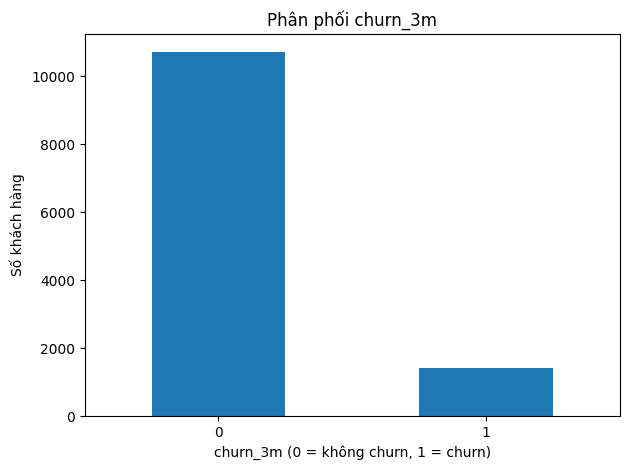

In [ ]:
# Kiểu dữ liệu
print("=== KIỂU DỮ LIỆU ===")
display(train.dtypes.rename("data_type").to_frame())

# Thống kê dữ liệu số
print("=== THỐNG KÊ DỮ LIỆU SỐ ===")
display(train.describe().T)

# Số lượng và tỷ lệ ô thiếu
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": (train.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

print("=== MISSING VALUES ===")
display(missing[missing["missing_count"] > 0])

# Dòng trùng lặp
print("Số dòng trùng hoàn toàn:", train.duplicated().sum())
print("Số customer_id trùng:", train["customer_id"].duplicated().sum())

# Phân phối biến mục tiêu
print("=== PHÂN PHỐI CHURN ===")
display(
    train["churn_3m"]
    .value_counts(dropna=False)
    .rename_axis("churn_3m")
    .to_frame("count")
)

print("Tỷ lệ churn (%):")
display((train["churn_3m"].value_counts(normalize=True) * 100).round(2))

# Biểu đồ tỷ lệ churn
train["churn_3m"].value_counts().sort_index().plot(
    kind="bar", rot=0, title="Phân phối churn_3m"
)
plt.xlabel("churn_3m (0 = không churn, 1 = churn)")
plt.ylabel("Số khách hàng")
plt.tight_layout()
plt.show()

In [6]:
import pandas as pd
import re
import unicodedata

# Chuẩn hóa khoảng trắng và các giá trị chữ
text_cols = train.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    train[col] = train[col].astype("string").str.strip()


# =========================
# 1. CHUẨN HÓA GENDER
# =========================
if "gender" in train.columns:
    gender_map = {
        "F": "F",
        "FEMALE": "F",
        "NỮ": "F",
        "NU": "F",
        "M": "M",
        "MALE": "M",
        "NAM": "M"
    }

    train["gender"] = (
        train["gender"]
        .str.strip()
        .str.upper()
        .replace(gender_map)
    )

    # Các giá trị không hợp lệ chuyển thành NA
    train.loc[~train["gender"].isin(["F", "M"]), "gender"] = pd.NA


# =========================
# 2. HÀM CHUẨN HÓA TÊN
# =========================
def normalize_name(value):
    if pd.isna(value):
        return None

    value = str(value).strip().lower()
    value = unicodedata.normalize("NFD", value)
    value = "".join(
        c for c in value
        if unicodedata.category(c) != "Mn"
    )
    value = value.replace("đ", "d")
    value = re.sub(r"[.\-_]", " ", value)
    value = re.sub(r"\s+", " ", value).strip()

    return value


# =========================
# 3. CHUẨN HÓA PROVINCE
# =========================
if "province" in train.columns:

    province_map = {
        # TP. Hồ Chí Minh
        "hcm": "HCM",
        "tp hcm": "HCM",
        "tphcm": "HCM",
        "tp ho chi minh": "HCM",
        "thanh pho ho chi minh": "HCM",
        "ho chi minh": "HCM",
        "ho chi minh city": "HCM",
        "sai gon": "HCM",

        # Hà Nội
        "ha noi": "Hà Nội",
        "hn": "Hà Nội",
        "hanoi": "Hà Nội",
        "thu do ha noi": "Hà Nội",

        # Đà Nẵng
        "da nang": "Đà Nẵng",
        "danang": "Đà Nẵng",

        # Bà Rịa - Vũng Tàu
        "ba ria vung tau": "Bà Rịa - Vũng Tàu",
        "br vt": "Bà Rịa - Vũng Tàu",
        "brvt": "Bà Rịa - Vũng Tàu",

        # Huế
        "hue": "Thừa Thiên Huế",
        "thua thien hue": "Thừa Thiên Huế",
        "thuathienhue": "Thừa Thiên Huế",
        "tt hue": "Thừa Thiên Huế",
        "tt-hue": "Thừa Thiên Huế",

        # Các tỉnh có dấu và không dấu
        "hai phong": "Hải Phòng",
        "binh duong": "Bình Dương",
        "can tho": "Cần Thơ",
        "dong nai": "Đồng Nai",
        "khanh hoa": "Khánh Hòa",
        "quang ninh": "Quảng Ninh",
        "nghe an": "Nghệ An",
        "bac ninh": "Bắc Ninh",
        "thanh hoa": "Thanh Hóa",
        "hai duong": "Hải Dương",
        "lam dong": "Lâm Đồng",
        "thua thien hue": "Thừa Thiên Huế",
        "thai nguyen": "Thái Nguyên",
        "nam dinh": "Nam Định",
        "long an": "Long An",
        "binh dinh": "Bình Định"
    }

    # Tạo mapping tự động cho tên có dấu, không dấu,
    # viết hoa, viết thường và dấu chấm/gạch
    normalized_map = {
        normalize_name(key): value
        for key, value in province_map.items()
    }

    # Bổ sung tên chuẩn để xử lý dữ liệu vốn đã có dấu
    canonical_names = [
        "HCM", "Hà Nội", "Hải Phòng", "Đà Nẵng",
        "Bình Dương", "Cần Thơ", "Đồng Nai", "Khánh Hòa",
        "Quảng Ninh", "Nghệ An", "Bắc Ninh", "Thanh Hóa",
        "Hải Dương", "Lâm Đồng", "Thừa Thiên Huế",
        "Thái Nguyên", "Nam Định", "Bà Rịa - Vũng Tàu",
        "Long An", "Bình Định"
    ]

    for name in canonical_names:
        normalized_map[normalize_name(name)] = name

    train["province"] = train["province"].apply(
        lambda x: (
            pd.NA if pd.isna(x) or str(x).strip() == ""
            else normalized_map.get(normalize_name(x), str(x).strip())
        )
    )


# =========================
# 4. KIỂM TRA KẾT QUẢ
# =========================
if "gender" in train.columns:
    print("Gender sau chuẩn hóa:")
    display(train["gender"].value_counts(dropna=False))

if "province" in train.columns:
    print("Province sau chuẩn hóa:")
    display(train["province"].value_counts(dropna=False))

    print("\nCác giá trị province còn lại cần kiểm tra:")
    display(
        train.loc[
            train["province"].notna(),
            "province"
        ].value_counts().to_frame("count")
    )

    print("\nSố lượng province khác nhau:",
          train["province"].nunique(dropna=True))

    print("Số province bị thiếu:",
          train["province"].isna().sum())

print("\n=== KIỂM TRA GIÁ TRỊ CỰC ĐOAN ===")

for col in [
    "age",
    "income_month",
    "credit_limit",
    "utilization_6m",
    "txn_count_3m",
    "txn_amount_3m",
    "spend_change_pct",
    "app_logins_30d",
    "other_bank_cards"
]:
    if col in train.columns:
        print(f"\n{col}")
        print(train[col].describe(
            percentiles=[0.01, 0.05, 0.95, 0.99]
        ))

Gender sau chuẩn hóa:


gender
F       6371
M       5518
<NA>     231
Name: count, dtype: Int64

Province sau chuẩn hóa:


province
HCM                  3758
Hà Nội               3665
Đà Nẵng               703
Hải Phòng             639
Bình Dương            424
Cần Thơ               408
Đồng Nai              293
Khánh Hòa             236
Quảng Ninh            206
<NA>                  201
Nghệ An               200
Bắc Ninh              187
Thanh Hóa             178
Thừa Thiên Huế        138
Hải Dương             121
Bà Rịa - Vũng Tàu     107
Lâm Đồng              104
Thái Nguyên            89
Nam Định               87
Long An                83
Bình Định              64
An Giang               64
Kiên Giang             61
Đắk Lắk                41
Vĩnh Phúc              37
Vũng Tàu               26
Name: count, dtype: Int64


Các giá trị province còn lại cần kiểm tra:


,count
province,
HCM,3758
Hà Nội,3665
Đà Nẵng,703
Hải Phòng,639
Bình Dương,424
Cần Thơ,408
Đồng Nai,293
Khánh Hòa,236
Quảng Ninh,206



Số lượng province khác nhau: 25
Số province bị thiếu: 201

=== KIỂM TRA GIÁ TRỊ CỰC ĐOAN ===

age
count    11724.000000
mean        39.743262
std         29.936281
min          0.000000
1%          19.000000
5%          22.000000
95%         63.000000
99%         73.000000
max        999.000000
Name: age, dtype: float64

income_month
count    1.055800e+04
mean     1.875843e+05
std      2.065907e+06
min      1.000000e+00
1%       3.300000e+00
5%       5.900000e+00
95%      4.750000e+01
99%      2.064126e+06
max      5.050000e+07
Name: income_month, dtype: float64

credit_limit
count    1.212000e+04
mean     1.094113e+06
std      1.052716e+07
min      1.000000e+01
1%       1.000000e+01
5%       1.500000e+01
95%      1.900000e+02
99%      4.000000e+07
max      3.850000e+08
Name: credit_limit, dtype: float64

utilization_6m
count    12120.000000
mean         0.324856
std          0.724755
min         -1.000000
1%           0.000000
5%           0.000000
95%          0.651050
99%          

=== KIỂM TRA OPEN_DATE ===
Tổng số dòng: 12120
Ngày hợp lệ: 11427
Ngày không chuyển đổi được: 693
Định dạng YYYY-MM-DD: 8403
Định dạng DD/MM/YYYY: 3024

Các giá trị open_date không đọc được:


26     20250803
48     20250610
62     20260528
74     20240919
87     20250125
114    20210625
135    20240805
136    20230304
163    20250924
164    20250825
208    20221104
248    20241128
277    20240804
301    20190606
317    20240310
333    20240909
359    20230528
433    20250828
444    20211003
462    20220705
Name: open_date, dtype: string


=== THỐNG KÊ NGÀY MỞ TÀI KHOẢN ===
Ngày sớm nhất: 2011-06-21 00:00:00
Ngày muộn nhất: 2026-06-12 00:00:00


,open_year,customer_count
0,2011.0,10
1,2012.0,11
2,2013.0,10
3,2014.0,27
4,2015.0,44
5,2016.0,82
6,2017.0,114
7,2018.0,196
8,2019.0,344
9,2020.0,531


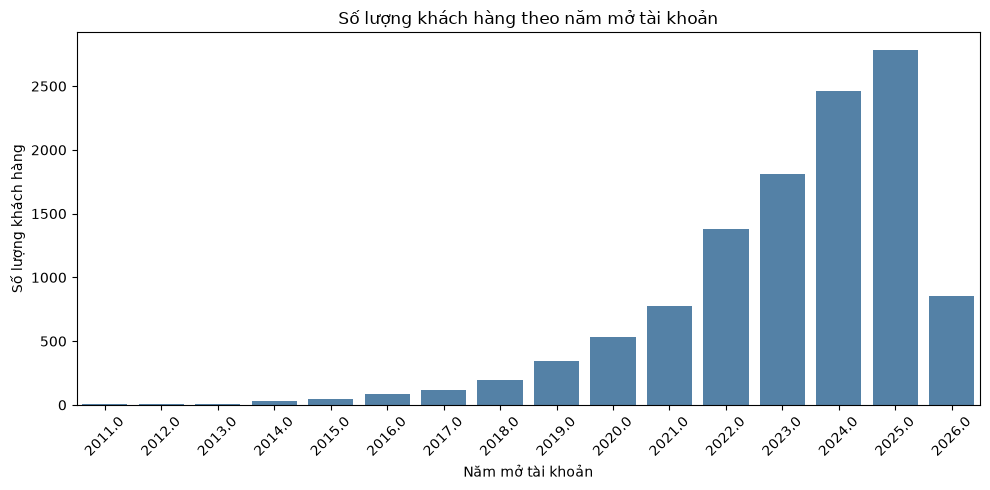


=== CHURN THEO NĂM MỞ TÀI KHOẢN ===


,open_year,customer_count,churn_rate,churn_rate_pct
0,2011.0,10,0.300000,30.000000
1,2012.0,11,0.090909,9.090909
2,2013.0,10,0.100000,10.000000
3,2014.0,27,0.037037,3.703704
4,2015.0,44,0.022727,2.272727
5,2016.0,82,0.036585,3.658537
6,2017.0,114,0.114035,11.403509
7,2018.0,196,0.096939,9.693878
8,2019.0,344,0.119186,11.918605
9,2020.0,531,0.111111,11.111111


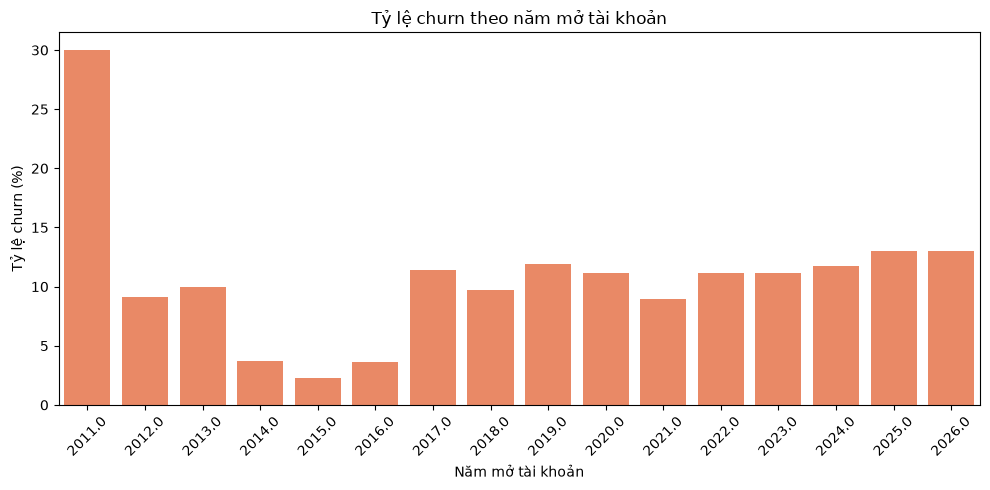


=== PHÂN TÍCH CHURN THEO NHÓM ===

--- Churn theo gender ---


,gender,customer_count,churn_rate,churn_rate_pct
0,F,6371,0.121017,12.101711
1,M,5518,0.111816,11.181588
2,<NA>,231,0.108225,10.822511


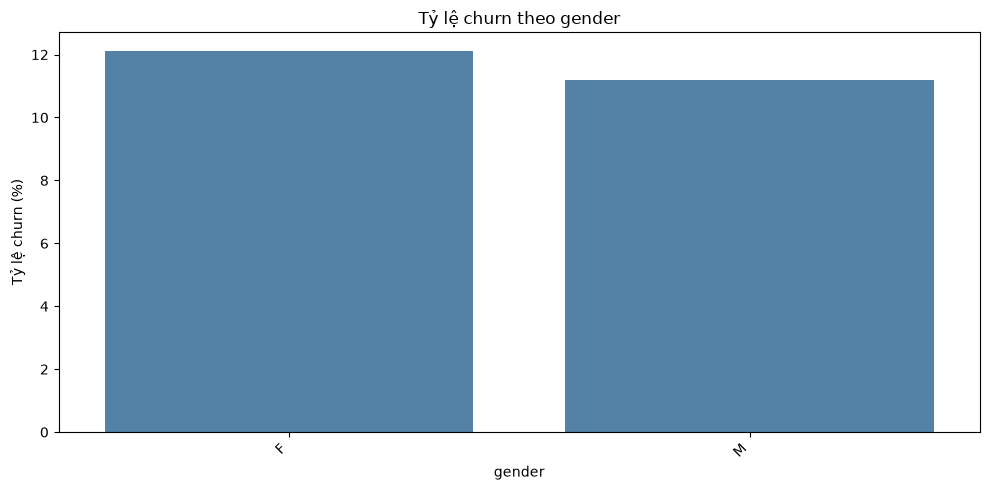


--- Churn theo occupation ---


,occupation,customer_count,churn_rate,churn_rate_pct
2,Retired,130,0.400000,40.000000
9,retired,718,0.363510,36.350975
6,Student,52,0.211538,21.153846
13,student,281,0.202847,20.284698
14,<NA>,614,0.133550,13.355049
4,Salaried,262,0.114504,11.450382
12,self_employed,2098,0.102002,10.200191
8,other,998,0.101202,10.120240
10,salaried,4934,0.088569,8.856911
7,civil_servant,1079,0.088044,8.804449


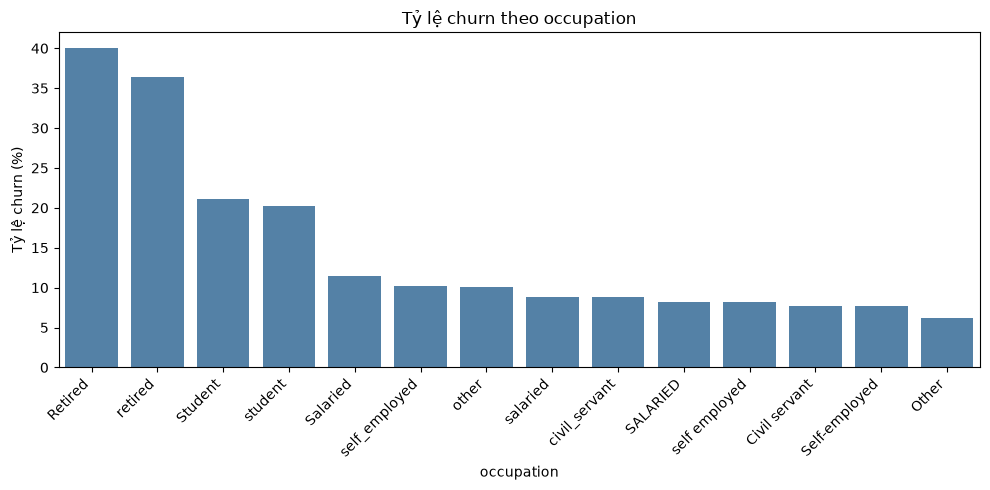


--- Churn theo last_contact_channel ---


,last_contact_channel,customer_count,churn_rate,churn_rate_pct
1,branch,2352,0.121173,12.117347
2,hotline,1388,0.118876,11.887608
0,app,4433,0.118204,11.820438
3,none,3432,0.111597,11.159674
4,<NA>,515,0.108738,10.873786


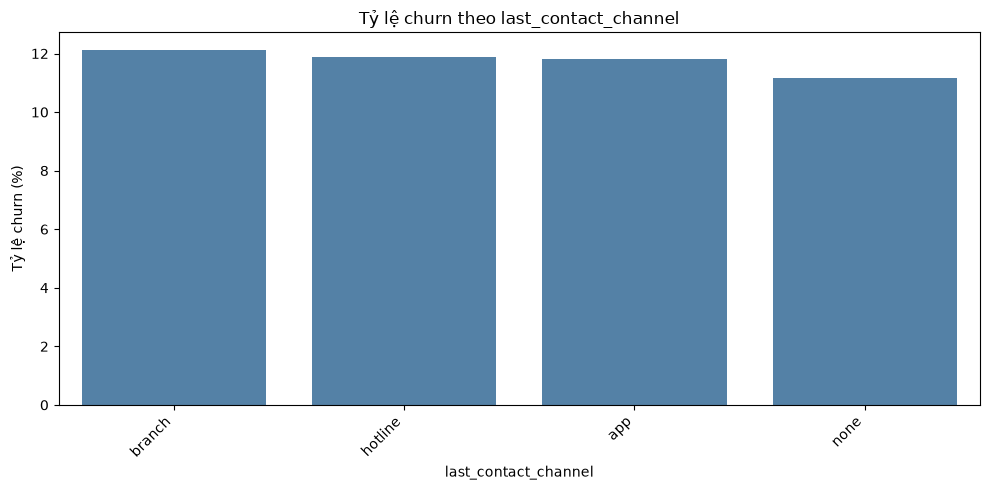


--- Churn theo promo_ended_60d ---


,promo_ended_60d,customer_count,churn_rate,churn_rate_pct
1,1,2372,0.206998,20.699831
0,0,9748,0.094584,9.458350


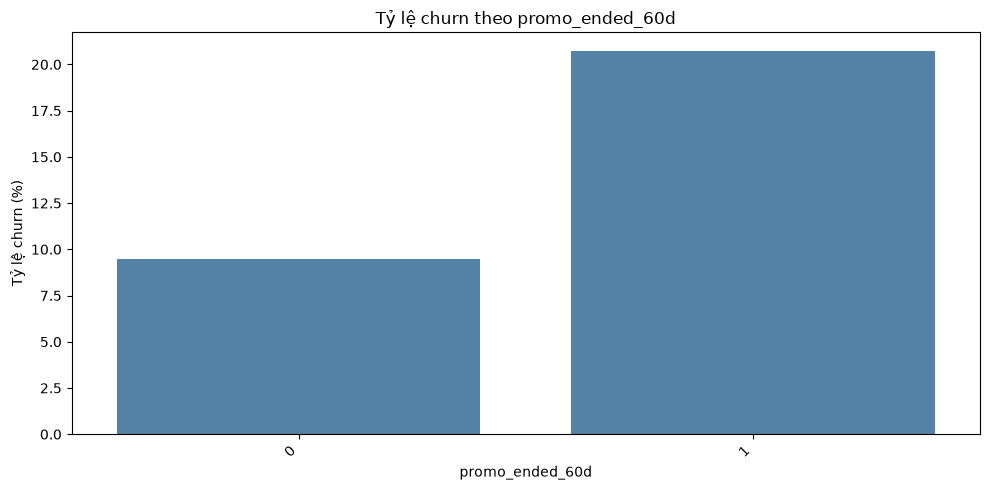


--- Churn theo salary_via_bank ---


,salary_via_bank,customer_count,churn_rate,churn_rate_pct
0,N,7878,0.135567,13.556740
2,<NA>,718,0.121170,12.116992
1,Y,3524,0.073212,7.321226


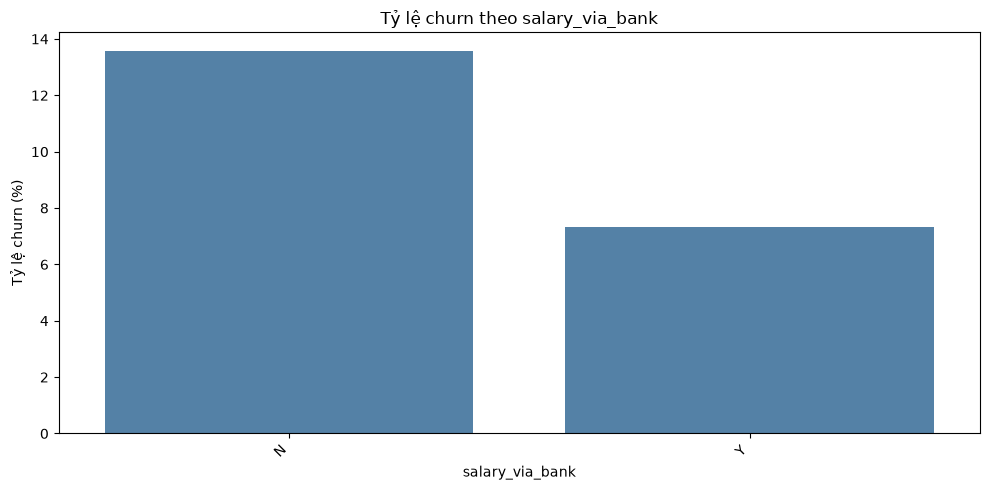


=== HOÀN THÀNH CELL 5 ===
Đã kiểm tra ngày mở tài khoản và phân tích churn theo nhóm.


In [7]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Làm việc trên bản sao, không sửa dữ liệu gốc
eda_date = train.copy()

# ------------------------------------------------------------
# 1. CHUẨN HÓA open_date
# ------------------------------------------------------------

if "open_date" in eda_date.columns:
    original_date = eda_date["open_date"].copy()
    date_text = original_date.astype("string").str.strip()

    # Nhận diện định dạng YYYY-MM-DD
    mask_iso = date_text.str.match(
        r"^\d{4}-\d{1,2}-\d{1,2}$",
        na=False
    )

    # Nhận diện định dạng DD/MM/YYYY
    mask_dmy = date_text.str.match(
        r"^\d{1,2}/\d{1,2}/\d{4}$",
        na=False
    )

    parsed_date = pd.Series(
        pd.NaT,
        index=eda_date.index,
        dtype="datetime64[ns]"
    )

    parsed_date.loc[mask_iso] = pd.to_datetime(
        date_text.loc[mask_iso],
        format="%Y-%m-%d",
        errors="coerce"
    )

    parsed_date.loc[mask_dmy] = pd.to_datetime(
        date_text.loc[mask_dmy],
        format="%d/%m/%Y",
        errors="coerce"
    )

    # Các định dạng khác được giữ là NaT để kiểm tra
    eda_date["open_date"] = parsed_date

    print("=== KIỂM TRA OPEN_DATE ===")
    print("Tổng số dòng:", len(eda_date))
    print("Ngày hợp lệ:", eda_date["open_date"].notna().sum())
    print("Ngày không chuyển đổi được:", eda_date["open_date"].isna().sum())
    print("Định dạng YYYY-MM-DD:", mask_iso.sum())
    print("Định dạng DD/MM/YYYY:", mask_dmy.sum())

    # Hiển thị các giá trị ngày không đọc được
    invalid_dates = original_date[
        eda_date["open_date"].isna()
        & original_date.notna()
        & original_date.astype("string").str.strip().ne("")
    ]

    if len(invalid_dates) > 0:
        print("\nCác giá trị open_date không đọc được:")
        display(invalid_dates.drop_duplicates().head(20))

    # --------------------------------------------------------
    # 2. PHÂN TÍCH PHÂN PHỐI NGÀY MỞ TÀI KHOẢN
    # --------------------------------------------------------

    valid_dates = eda_date["open_date"].dropna()

    if len(valid_dates) > 0:
        print("\n=== THỐNG KÊ NGÀY MỞ TÀI KHOẢN ===")
        print("Ngày sớm nhất:", valid_dates.min())
        print("Ngày muộn nhất:", valid_dates.max())

        eda_date["open_year"] = eda_date["open_date"].dt.year
        eda_date["open_month"] = eda_date["open_date"].dt.month

        yearly_accounts = (
            eda_date.dropna(subset=["open_year"])
            .groupby("open_year")
            .size()
            .rename("customer_count")
            .reset_index()
        )

        display(yearly_accounts)

        plt.figure(figsize=(10, 5))
        sns.countplot(
            data=eda_date.dropna(subset=["open_year"]),
            x="open_year",
            order=sorted(
                eda_date["open_year"].dropna().unique()
            ),
            color="steelblue"
        )
        plt.title("Số lượng khách hàng theo năm mở tài khoản")
        plt.xlabel("Năm mở tài khoản")
        plt.ylabel("Số lượng khách hàng")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

        # ----------------------------------------------------
        # 3. TỶ LỆ CHURN THEO NĂM MỞ TÀI KHOẢN
        # ----------------------------------------------------

        if "churn_3m" in eda_date.columns:
            yearly_churn = (
                eda_date.dropna(subset=["open_year", "churn_3m"])
                .groupby("open_year")
                .agg(
                    customer_count=("churn_3m", "size"),
                    churn_rate=("churn_3m", "mean")
                )
                .reset_index()
            )

            yearly_churn["churn_rate_pct"] = (
                yearly_churn["churn_rate"] * 100
            )

            print("\n=== CHURN THEO NĂM MỞ TÀI KHOẢN ===")
            display(yearly_churn)

            plt.figure(figsize=(10, 5))
            sns.barplot(
                data=yearly_churn,
                x="open_year",
                y="churn_rate_pct",
                color="coral"
            )
            plt.title("Tỷ lệ churn theo năm mở tài khoản")
            plt.xlabel("Năm mở tài khoản")
            plt.ylabel("Tỷ lệ churn (%)")
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

else:
    print("Không tìm thấy cột open_date trong dữ liệu.")

# ------------------------------------------------------------
# 4. PHÂN TÍCH CHURN THEO CÁC NHÓM KHÁCH HÀNG
# ------------------------------------------------------------

if "churn_3m" in train.columns:
    print("\n=== PHÂN TÍCH CHURN THEO NHÓM ===")

    group_cols = [
        "gender",
        "occupation",
        "last_contact_channel",
        "promo_ended_60d",
        "salary_via_bank"
    ]

    for col in group_cols:
        if col not in train.columns:
            continue

        summary = (
            train.groupby(col, dropna=False)
            .agg(
                customer_count=("churn_3m", "size"),
                churn_rate=("churn_3m", "mean")
            )
            .reset_index()
        )

        summary["churn_rate_pct"] = (
            summary["churn_rate"] * 100
        )

        summary = summary.sort_values(
            "churn_rate_pct",
            ascending=False
        )

        print(f"\n--- Churn theo {col} ---")
        display(summary)

        # Vẽ biểu đồ khi số nhóm không quá lớn
        if len(summary) <= 20:
            plt.figure(figsize=(10, 5))

            sns.barplot(
                data=summary,
                x=col,
                y="churn_rate_pct",
                color="steelblue"
            )

            plt.title(f"Tỷ lệ churn theo {col}")
            plt.xlabel(col)
            plt.ylabel("Tỷ lệ churn (%)")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            plt.show()

# ------------------------------------------------------------
# 5. TỔNG KẾT CELL 5
# ------------------------------------------------------------

print("\n=== HOÀN THÀNH CELL 5 ===")
print("Đã kiểm tra ngày mở tài khoản và phân tích churn theo nhóm.")

In [4]:
print("=== KIỂM TRA TRÙNG LẶP ===")

print("Trùng hoàn toàn:", train.duplicated().sum())

if "customer_id" in train.columns:
    print(
        "Số dòng có customer_id trùng:",
        train["customer_id"].duplicated().sum()
    )

duplicate_customers = train[
    train.duplicated(subset=["customer_id"], keep=False)
].sort_values("customer_id")

display(duplicate_customers.head(30))

=== KIỂM TRA TRÙNG LẶP ===
Trùng hoàn toàn: 120
Số dòng có customer_id trùng: 120


,customer_id,bank_code,age,gender,province,occupation,income_month,card_type,open_date,credit_limit,...,spend_change_pct,app_logins_30d,complaints_12m,late_payments_12m,salary_via_bank,other_bank_cards,promo_ended_60d,last_contact_channel,currency,churn_3m
9576,CUS001JYYD,VB01,31.0,M,Thanh Hóa,other,15.1,Classic,2026-01-21,35.0,...,16.1,6.0,0,0,N,1.0,0,app,VND,0
6360,CUS001JYYD,VB01,31.0,M,Thanh Hóa,other,15.1,Classic,2026-01-21,35.0,...,16.1,6.0,0,0,N,1.0,0,app,VND,0
9911,CUS02C7RJN,VB01,61.0,M,Hà Nội,retired,23.3,Gold,05/04/2019,60.0,...,-9.4,2.0,0,0,N,1.0,0,none,VND,0
1144,CUS02C7RJN,VB01,61.0,M,Hà Nội,retired,23.3,Gold,05/04/2019,60.0,...,-9.4,2.0,0,0,N,1.0,0,none,VND,0
10791,CUS095475P,VB01,22.0,F,Hải Phòng,salaried,20.4,Gold,03/05/2025,60.0,...,-8.1,28.0,0,0,Y,2.0,0,NaN,VND,0
10859,CUS095475P,VB01,22.0,F,Hải Phòng,salaried,20.4,Gold,03/05/2025,60.0,...,-8.1,28.0,0,0,Y,2.0,0,NaN,VND,0
11179,CUS0D1Z5GM,VB01,43.0,F,Hà Nội,Self-employed,17.4,Classic,06/11/2021,25.0,...,12.3,4.0,1,0,N,2.0,0,none,VND,0
7493,CUS0D1Z5GM,VB01,43.0,F,Hà Nội,Self-employed,17.4,Classic,06/11/2021,25.0,...,12.3,4.0,1,0,N,2.0,0,none,VND,0
1014,CUS0OSN9BB,VB01,33.0,F,Cần Thơ,self_employed,15.8,Classic,27/02/2022,40.0,...,14.1,3.0,0,0,Y,0.0,0,none,VND,0
5303,CUS0OSN9BB,VB01,33.0,F,Cần Thơ,self_employed,15.8,Classic,27/02/2022,40.0,...,14.1,3.0,0,0,Y,0.0,0,none,VND,0


In [ ]:
# Kiểm tra định dạng ngày mở tài khoản
print("Một số giá trị open_date:")
display(train["open_date"].value_counts(dropna=False).head(15))

# Chuẩn hóa ngày có nhiều định dạng
train["open_date"] = pd.to_datetime(
    train["open_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Số ngày mở tài khoản không đọc được:",
      train["open_date"].isna().sum())

# Tỷ lệ churn theo giới tính
if "gender" in train.columns:
    print("\nTỷ lệ churn theo gender:")
    display(
        train.groupby("gender", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
    )

# Tỷ lệ churn theo nghề nghiệp
if "occupation" in train.columns:
    print("\nTỷ lệ churn theo occupation:")
    display(
        train.groupby("occupation", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
        .sort_values("churn_percent", ascending=False)
    )

# Tỷ lệ churn theo kênh liên hệ gần nhất
if "last_contact_channel" in train.columns:
    print("\nTỷ lệ churn theo last_contact_channel:")
    display(
        train.groupby("last_contact_channel", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
        .sort_values("churn_percent", ascending=False)
    )

# So sánh churn theo việc kết thúc khuyến mãi gần đây
if "promo_ended_60d" in train.columns:
    print("\nTỷ lệ churn theo promo_ended_60d:")
    display(
        train.groupby("promo_ended_60d", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
    )

Một số giá trị open_date:


,count
open_date,
<NA>,78
2025-05-03,17
2022-07-09,16
2024-07-10,15
2024-05-24,15
2024-08-31,15
2025-03-27,15
2025-10-11,15
2024-12-06,14


Số ngày mở tài khoản không đọc được: 78

Tỷ lệ churn theo gender:


,count,mean,churn_percent
gender,,,
F,6371,0.121017,12.10
M,5518,0.111816,11.18
<NA>,231,0.108225,10.82



Tỷ lệ churn theo occupation:


,count,mean,churn_percent
occupation,,,
Retired,130,0.400000,40.00
retired,718,0.363510,36.35
Student,52,0.211538,21.15
student,281,0.202847,20.28
<NA>,614,0.133550,13.36
Salaried,262,0.114504,11.45
self_employed,2098,0.102002,10.20
other,998,0.101202,10.12
salaried,4934,0.088569,8.86



Tỷ lệ churn theo last_contact_channel:


,count,mean,churn_percent
last_contact_channel,,,
branch,2352,0.121173,12.12
hotline,1388,0.118876,11.89
app,4433,0.118204,11.82
none,3432,0.111597,11.16
<NA>,515,0.108738,10.87



Tỷ lệ churn theo promo_ended_60d:


,count,mean,churn_percent
promo_ended_60d,,,
0,9748,0.094584,9.46
1,2372,0.206998,20.70


In [8]:


%%writefile clean_data.py
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd


def normalize_text(value):
    """Chuẩn hóa chữ để so khớp các biến thể."""
    if pd.isna(value):
        return None

    value = str(value).strip().lower()
    value = unicodedata.normalize("NFD", value)
    value = "".join(
        c for c in value
        if unicodedata.category(c) != "Mn"
    )
    value = value.replace("đ", "d")
    value = re.sub(r"[.\-_]", " ", value)
    value = re.sub(r"\s+", " ", value).strip()

    return value


def clean_data(df):
    """Làm sạch dữ liệu Credit Card Churn."""
    df = df.copy()

    # 1. Chuẩn hóa khoảng trắng
    for col in df.select_dtypes(
        include=["object", "string"]
    ).columns:
        df[col] = df[col].astype("string").str.strip()

    # 2. Lưu lại thông tin giá trị thiếu ban đầu
    missing_cols = [
        "gender", "province", "age", "income_month",
        "other_bank_cards", "occupation", "open_date",
        "app_logins_30d", "salary_via_bank",
        "last_contact_channel"
    ]

    for col in missing_cols:
        if col in df.columns:
            df[f"{col}_was_missing"] = (
                df[col].isna().astype("int8")
            )

    # 3. Chuẩn hóa giới tính
    if "gender" in df.columns:
        gender_map = {
            "f": "F",
            "female": "F",
            "nu": "F",
            "nữ": "F",
            "m": "M",
            "male": "M",
            "nam": "M"
        }

        df["gender"] = df["gender"].apply(
            lambda x: gender_map.get(str(x).strip().lower(), pd.NA)
            if pd.notna(x) else pd.NA
        )

    # 4. Chuẩn hóa tỉnh thành
    if "province" in df.columns:
        province_map = {
            "hcm": "HCM",
            "tp hcm": "HCM",
            "tphcm": "HCM",
            "tp ho chi minh": "HCM",
            "thanh pho ho chi minh": "HCM",
            "ho chi minh": "HCM",
            "ho chi minh city": "HCM",
            "sai gon": "HCM",
            "ha noi": "Hà Nội",
            "hanoi": "Hà Nội",
            "hn": "Hà Nội",
            "da nang": "Đà Nẵng",
            "hai phong": "Hải Phòng",
            "binh duong": "Bình Dương",
            "can tho": "Cần Thơ",
            "dong nai": "Đồng Nai",
            "khanh hoa": "Khánh Hòa",
            "quang ninh": "Quảng Ninh",
            "nghe an": "Nghệ An",
            "bac ninh": "Bắc Ninh",
            "thanh hoa": "Thanh Hóa",
            "hai duong": "Hải Dương",
            "lam dong": "Lâm Đồng",
            "thai nguyen": "Thái Nguyên",
            "nam dinh": "Nam Định",
            "long an": "Long An",
            "binh dinh": "Bình Định",
            "ba ria vung tau": "Bà Rịa - Vũng Tàu",
            "ba ria vung tau province": "Bà Rịa - Vũng Tàu",
            "br vt": "Bà Rịa - Vũng Tàu",
            "brvt": "Bà Rịa - Vũng Tàu",
            "hue": "Thừa Thiên Huế",
            "thua thien hue": "Thừa Thiên Huế",
            "tt hue": "Thừa Thiên Huế"
        }

        df["province"] = df["province"].apply(
            lambda x: (
                pd.NA if pd.isna(x) or str(x).strip() == ""
                else province_map.get(normalize_text(x), str(x).strip())
            )
        )

    # 5. Chuyển các cột số về dạng numeric
    numeric_cols = [
        "age", "income_month", "other_bank_cards",
        "credit_limit", "utilization_6m",
        "txn_count_3m", "txn_amount_3m",
        "spend_change_pct", "app_logins_30d",
        "complaints_12m", "late_payments_12m"
    ]

    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # 6. Kiểm tra tuổi bất thường
    if "age" in df.columns:
        invalid = (df["age"] < 18) | (df["age"] > 100)

        df["age_outlier_flag"] = (
            invalid.fillna(False).astype("int8")
        )
        df.loc[invalid, "age"] = np.nan

    # 7. Kiểm tra thu nhập và số thẻ âm
    for col in ["income_month", "other_bank_cards"]:
        if col in df.columns:
            invalid = df[col] < 0

            df[f"{col}_invalid_flag"] = (
                invalid.fillna(False).astype("int8")
            )
            df.loc[invalid, col] = np.nan

    # 8. Kiểm tra biến đếm âm
    count_cols = [
        "other_bank_cards", "txn_count_3m",
        "app_logins_30d", "complaints_12m",
        "late_payments_12m"
    ]

    for col in count_cols:
        if col in df.columns:
            invalid = df[col] < 0

            df[f"{col}_negative_flag"] = (
                invalid.fillna(False).astype("int8")
            )
            df.loc[invalid, col] = np.nan

    # 9. Kiểm tra tỷ lệ sử dụng thẻ
    if "utilization_6m" in df.columns:
        invalid = ~df["utilization_6m"].between(0, 1)

        df["utilization_6m_invalid_flag"] = (
            invalid.fillna(False).astype("int8")
        )
        df.loc[invalid, "utilization_6m"] = np.nan

    # 10. Chuẩn hóa ngày mở tài khoản
    if "open_date" in df.columns:
        s = df["open_date"].astype("string").str.strip()

        iso = s.str.match(
            r"^\d{4}-\d{1,2}-\d{1,2}$", na=False
        )
        dmy = s.str.match(
            r"^\d{1,2}/\d{1,2}/\d{4}$", na=False
        )

        parsed = pd.Series(
            pd.NaT, index=df.index, dtype="datetime64[ns]"
        )

        parsed.loc[iso] = pd.to_datetime(
            s.loc[iso], format="%Y-%m-%d", errors="coerce"
        )
        parsed.loc[dmy] = pd.to_datetime(
            s.loc[dmy], format="%d/%m/%Y", errors="coerce"
        )

        df["open_date"] = parsed

    # 11. Loại bản ghi trùng hoàn toàn
    duplicates_removed = int(df.duplicated().sum())
    df = df.drop_duplicates(keep="first").copy()

    # 12. Điền giá trị thiếu bằng trung vị cho biến số
    # Không điền target hoặc customer_id
    protected = {"customer_id", "churn_3m"}

    for col in df.select_dtypes(include=["number"]).columns:
        if col in protected or col.endswith("_was_missing"):
            continue

        if df[col].isna().any():
            median = df[col].median()
            if pd.notna(median):
                df[col] = df[col].fillna(median)

    # 13. Điền giá trị thiếu cho biến phân loại
    for col in df.select_dtypes(
        include=["object", "string"]
    ).columns:
        if col not in protected:
            df[col] = df[col].fillna("Unknown")

    # Lưu số dòng trùng đã loại để báo cáo
    df.attrs["duplicates_removed"] = duplicates_removed

    return df



Writing clean_data.py


In [9]:

from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

# Tìm file clean_data.py
ROOT = Path.cwd().resolve()

if not (ROOT / "clean_data.py").exists():
    PROJECT_DIR = Path(
        r"C:\Users\USER\Downloads\ML-Kaggle-Project-main"
    )

    candidates = list(PROJECT_DIR.rglob("clean_data.py"))

    if not candidates:
        raise FileNotFoundError(
            "Không tìm thấy clean_data.py. Hãy chạy Cell 6 trước."
        )

    ROOT = candidates[0].parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Tải lại module nếu đã import trước đó
import importlib
import clean_data as cleaning_module

importlib.reload(cleaning_module)
clean_data = cleaning_module.clean_data

# Đọc lại dữ liệu gốc, không dùng dữ liệu đã sửa trong EDA
raw = pd.read_csv(DATA_FILE)

# Làm sạch
cleaned = clean_data(raw)

print("========== KẾT QUẢ LÀM SẠCH ==========")
print("File đầu vào:", DATA_FILE)
print("Số dòng ban đầu:", len(raw))
print("Số dòng sau làm sạch:", len(cleaned))
print(
    "Số dòng trùng hoàn toàn đã loại:",
    cleaned.attrs.get("duplicates_removed", 0)
)

print("\nSố giá trị thiếu ban đầu:")
display(
    raw.isna().sum()
    .loc[lambda x: x > 0]
    .to_frame("missing_before")
)

print("\nSố giá trị thiếu sau làm sạch:")
display(
    cleaned.isna().sum()
    .loc[lambda x: x > 0]
    .to_frame("missing_after")
)

print("\nSố lượng giá trị bất thường:")
for col in [
    "age_outlier_flag",
    "income_month_invalid_flag",
    "other_bank_cards_invalid_flag",
    "utilization_6m_invalid_flag"
]:
    if col in cleaned.columns:
        print(col, "=", int(cleaned[col].sum()))

# Xuất dữ liệu đã làm sạch
output_path = ROOT / "cleaned_churn.csv"
cleaned.to_csv(output_path, index=False)

print("\nĐã lưu file:", output_path)
display(cleaned.head())




========== KẾT QUẢ LÀM SẠCH ==========
File đầu vào: C:\Users\USER\Downloads\ML-Kaggle-Project-main\credit-card-churn\data\raw\train.csv
Số dòng ban đầu: 12120
Số dòng sau làm sạch: 12000
Số dòng trùng hoàn toàn đã loại: 120

Số giá trị thiếu ban đầu:


,missing_before
age,396
gender,231
province,201
occupation,614
income_month,1562
open_date,78
app_logins_30d,1516
salary_via_bank,718
other_bank_cards,2463
last_contact_channel,515



Số giá trị thiếu sau làm sạch:


,missing_after
open_date,684



Số lượng giá trị bất thường:
age_outlier_flag = 69
income_month_invalid_flag = 0
other_bank_cards_invalid_flag = 0
utilization_6m_invalid_flag = 85

Đã lưu file: C:\Users\USER\Downloads\ML-Kaggle-Project-main\credit-card-churn\notebooks\cleaned_churn.csv


,customer_id,bank_code,age,gender,province,occupation,income_month,card_type,open_date,credit_limit,...,last_contact_channel_was_missing,age_outlier_flag,income_month_invalid_flag,other_bank_cards_invalid_flag,other_bank_cards_negative_flag,txn_count_3m_negative_flag,app_logins_30d_negative_flag,complaints_12m_negative_flag,late_payments_12m_negative_flag,utilization_6m_invalid_flag
0,CUSTI3FNUD,VB01,48.0,F,Hải Dương,self_employed,25.1,Gold,2026-04-09,55.0,...,0,0,0,0,0,0,0,0,0,0
1,CUSOOYRASU,VB01,47.0,M,Hà Nội,Salaried,17.7,Classic,2024-01-06,30.0,...,0,0,0,0,0,0,0,0,0,0
2,CUSQTUBJRJ,VB01,38.0,M,Long An,other,8.5,Cashback,2022-08-02,15.0,...,0,0,0,0,0,0,0,0,0,0
3,CUSD7I53QY,VB01,25.0,M,HCM,self_employed,33.9,Cashback,2022-05-12,110.0,...,0,0,0,0,0,0,0,0,0,0
4,CUS02NC6FN,VB01,32.0,M,HCM,civil_servant,14.0,Cashback,2025-07-03,40.0,...,0,0,0,0,0,0,0,0,0,0


In [10]:

from pathlib import Path
from datetime import datetime

report_path = ROOT / "data_quality_report.md"

lines = [
    "# CREDIT CARD CHURN — DATA QUALITY REPORT",
    "",
    f"Ngày tạo báo cáo: {datetime.now():%d/%m/%Y %H:%M}",
    "",
    "## 1. Tổng quan",
    f"- Số dòng ban đầu: {len(raw):,}",
    f"- Số dòng sau làm sạch: {len(cleaned):,}",
    f"- Số cột ban đầu: {len(raw.columns)}",
    f"- Số cột sau làm sạch: {len(cleaned.columns)}",
    f"- Số dòng trùng hoàn toàn đã loại: "
    f"{cleaned.attrs.get('duplicates_removed', 0)}",
    "",
    "## 2. Giá trị thiếu trước làm sạch",
    "",
    "| Cột | Số lượng thiếu | Tỷ lệ thiếu (%) |",
    "|---|---:|---:|"
]

missing_before = raw.isna().sum()

for col, count in missing_before[missing_before > 0].items():
    rate = count / len(raw) * 100
    lines.append(f"| {col} | {count} | {rate:.2f}% |")

lines.extend([
    "",
    "## 3. Giá trị thiếu sau làm sạch",
    "",
    "| Cột | Số lượng thiếu |",
    "|---|---:|"
])

missing_after = cleaned.isna().sum()

if missing_after.sum() == 0:
    lines.append("| Không còn giá trị thiếu | 0 |")
else:
    for col, count in missing_after[missing_after > 0].items():
        lines.append(f"| {col} | {count} |")

lines.extend([
    "",
    "## 4. Các quy tắc làm sạch",
    "- Chuẩn hóa khoảng trắng và biến thể gender.",
    "- Chuẩn hóa một số biến thể tên tỉnh thành.",
    "- Chuyển các cột số về dạng numeric.",
    "- Đánh dấu tuổi dưới 18 hoặc trên 100 là bất thường.",
    "- Đánh dấu thu nhập âm và số thẻ âm.",
    "- Kiểm tra utilization_6m nằm trong khoảng 0 đến 1.",
    "- Chuẩn hóa open_date theo YYYY-MM-DD hoặc DD/MM/YYYY.",
    "- Loại các bản ghi trùng hoàn toàn.",
    "- Điền thiếu biến số bằng trung vị.",
    "- Điền thiếu biến phân loại bằng Unknown.",
    "- Giữ lại các cột đánh dấu giá trị thiếu và bất thường.",
    "",
    "## 5. Lưu ý",
    "- Chưa tự động xóa các dòng chỉ trùng customer_id.",
    "- Cần kiểm tra các dòng trùng customer_id trước khi quyết định.",
    "- Cần xác nhận đơn vị của utilization_6m trước khi áp dụng "
    "giới hạn 0–1.",
    "- Không loại bỏ outlier chỉ dựa vào giá trị lớn hoặc nhỏ.",
    "- Các cột đánh dấu bất thường giúp truy vết dữ liệu ban đầu.",
    "",
    "## 6. File đầu ra",
    f"- Dữ liệu đã làm sạch: `{output_path.name}`",
    f"- Script làm sạch: `clean_data.py`",
])

report_path.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

print("Đã tạo báo cáo:", report_path)
print("\n========== NỘI DUNG BÁO CÁO ==========\n")
print(report_path.read_text(encoding="utf-8"))


Đã tạo báo cáo: C:\Users\USER\Downloads\ML-Kaggle-Project-main\credit-card-churn\notebooks\data_quality_report.md

========== NỘI DUNG BÁO CÁO ==========

# CREDIT CARD CHURN — DATA QUALITY REPORT

Ngày tạo báo cáo: 25/10/2026 12:11

## 1. Tổng quan
- Số dòng ban đầu: 12,120
- Số dòng sau làm sạch: 12,000
- Số cột ban đầu: 24
- Số cột sau làm sạch: 43
- Số dòng trùng hoàn toàn đã loại: 120

## 2. Giá trị thiếu trước làm sạch

| Cột | Số lượng thiếu | Tỷ lệ thiếu (%) |
|---|---:|---:|
| age | 396 | 3.27% |
| gender | 231 | 1.91% |
| province | 201 | 1.66% |
| occupation | 614 | 5.07% |
| income_month | 1562 | 12.89% |
| open_date | 78 | 0.64% |
| app_logins_30d | 1516 | 12.51% |
| salary_via_bank | 718 | 5.92% |
| other_bank_cards | 2463 | 20.32% |
| last_contact_channel | 515 | 4.25% |

## 3. Giá trị thiếu sau làm sạch

| Cột | Số lượng thiếu |
|---|---:|
| open_date | 684 |

## 4. Các quy tắc làm sạch
- Chuẩn hóa khoảng trắng và biến thể gender.
- Chuẩn hóa một số biến thể tên tỉnh th